In [2]:
# Program 1: Load Iris dataset from CSV and explore it
import pandas as pd
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\iris_dataset.csv"      # <-- ch
df = pd.read_csv(FILE)
print("First 10 records:")
print(df.head(10))
print("\nRows and columns:", df.shape)
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nData types:")
print(df.dtypes)

First 10 records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

        target  
0  Iris-setosa  
1  Iris-setosa  
2  Iris-setosa  
3  Iris-setosa  
4  Iris-setosa  
5  Iris-se

In [3]:
# Program 2: Descriptive statistics on the Diamond dataset
import pandas as pd
from scipy import stats
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\diamonds.csv"  # <-- change to your file path
df = pd.read_csv(FILE)
num = df.select_dtypes(include="number")   # only numeric columns
for col in num.columns:
    x = num[col].dropna()
    print("\n===", col, "===")
    print("Mean            :", x.mean())
    print("Median          :", x.median())
    print("Mode            :", x.mode()[0])
    print("Std deviation   :", x.std())
    print("Variance        :", x.var())
    print("2nd moment      :", stats.moment(x, moment=2))
    print("3rd moment      :", stats.moment(x, moment=3))
    print("4th moment      :", stats.moment(x, moment=4))
    print("Skewness        :", stats.skew(x))
    print("Kurtosis        :", stats.kurtosis(x))


=== carat ===
Mean            : 0.7979397478680015
Median          : 0.7
Mode            : 0.3
Std deviation   : 0.47401124440538067
Variance        : 0.22468665982273753
2nd moment      : 0.2246824943303776
3rd moment      : 0.1189206464125235
4th moment      : 0.21487291967322675
Skewness        : 1.1166148681277792
Kurtosis        : 1.2564076184374757

=== depth ===
Mean            : 61.74940489432702
Median          : 61.8
Mode            : 62.0
Std deviation   : 1.4326213188337733
Variance        : 2.05240384317702
2nd moment      : 2.052365793420613
3rd moment      : -0.24195710813352916
4th moment      : 36.80949941222793
Skewness        : -0.08229173779624752
Kurtosis        : 5.738771345086846

=== table ===
Mean            : 57.45718390804598
Median          : 57.0
Mode            : 56.0
Std deviation   : 2.234490562820938
Variance        : 4.992948075335832
2nd moment      : 4.992855510486322
3rd moment      : 8.89022974083709
4th moment      : 144.62295743573333
Skewness  

In [5]:
# Program 3: Find missing values in Titanic and fill numeric ones with the mean
import pandas as pd
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\titanic.csv"   # <-- change to your file path
df = pd.read_csv(FILE)
print("Missing values before:")
print(df.isnull().sum())
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
   df[col] = df[col].fillna(df[col].mean())
print("\nMissing values after (numeric columns filled with mean):")
print(df.isnull().sum())


Missing values before:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing values after (numeric columns filled with mean):
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [6]:
# Program 4: Find and remove duplicate records in Titanic
import pandas as pd
FILE =r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\IMDB_Dataset.csv"  # <-- change to your file path
df = pd.read_csv(FILE)
print("Rows before:", len(df))
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows before: 50000
Duplicate rows: 418
Rows after removing duplicates: 49582


In [7]:
# Program 5: Detect outliers with the IQR method
import pandas as pd
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\titanic.csv" # <-- change to your file path
COLUMN = "Fare"                     # numerical column to check
df = pd.read_csv(FILE)
q1 = df[COLUMN].quantile(0.25)
q3 = df[COLUMN].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("Q1 =", q1, " Q3 =", q3, " IQR =", iqr)
print("Lower limit =", lower, " Upper limit =", upper)
outliers = df[(df[COLUMN] < lower) | (df[COLUMN] > upper)]
print("\nNumber of outliers:", len(outliers))
print(outliers)
clean = df[(df[COLUMN] >= lower) & (df[COLUMN] <= upper)]
print("\nData after removing outliers:", clean.shape)

Q1 = 7.9104  Q3 = 31.0  IQR = 23.0896
Lower limit = -26.724  Upper limit = 65.6344

Number of outliers: 116
     PassengerId  Survived  Pclass  \
1              2         1       1   
27            28         0       1   
31            32         1       1   
34            35         0       1   
52            53         1       1   
..           ...       ...     ...   
846          847         0       3   
849          850         1       1   
856          857         1       1   
863          864         0       3   
879          880         1       1   

                                                  Name     Sex   Age  SibSp  \
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
27                      Fortune, Mr. Charles Alexander    male  19.0      3   
31      Spencer, Mrs. William Augustus (Marie Eugenie)  female   NaN      1   
34                             Meyer, Mr. Edgar Joseph    male  28.0      1   
52            Harper, Mrs. Henry Sleeper

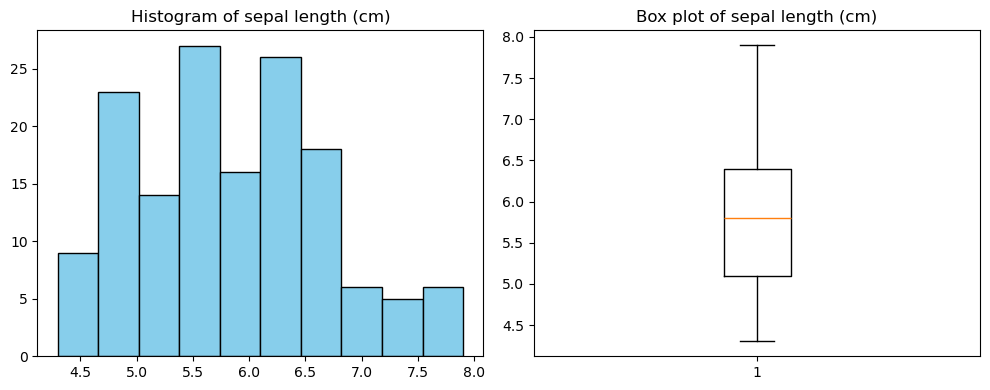

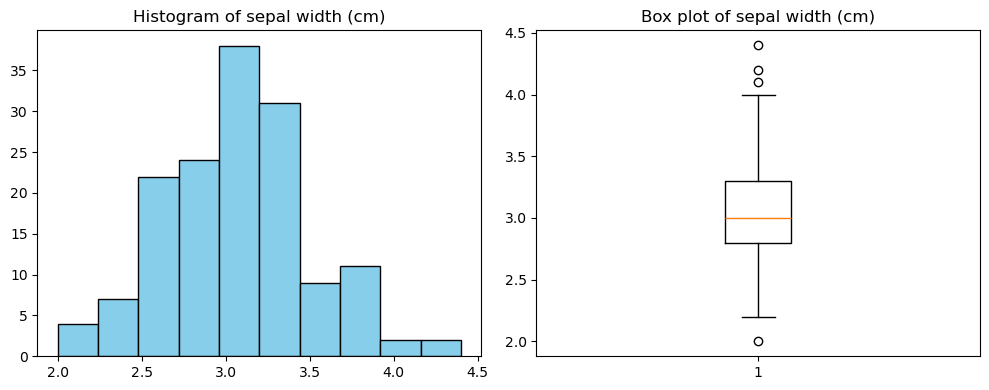

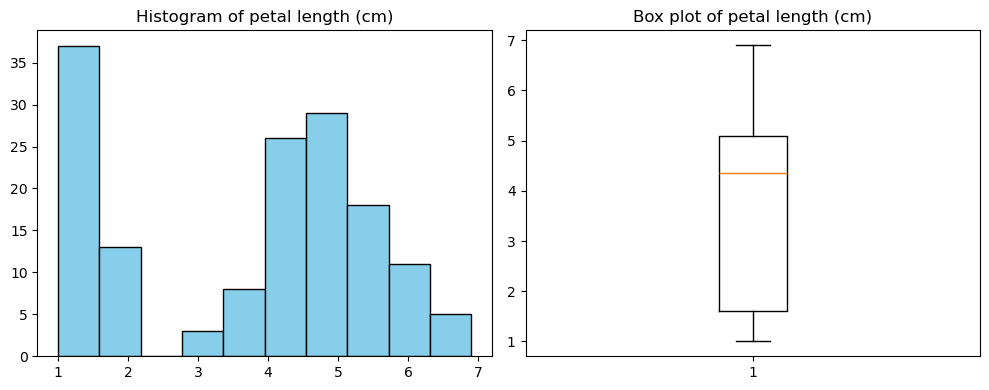

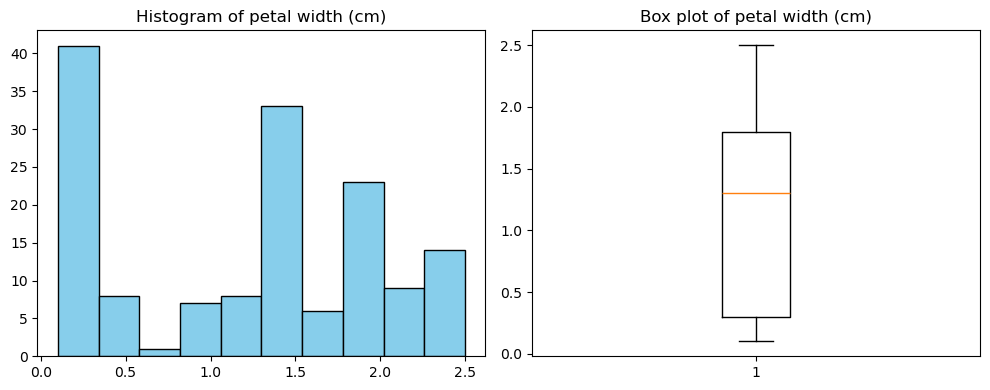

In [8]:
# Program 6: Histograms and box plots for a student dataset
import pandas as pd
import matplotlib.pyplot as plt
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\iris_dataset.csv" # <-- change to your file path
df = pd.read_csv(FILE)
cols = df.select_dtypes(include="number").columns[:4]   # first 4 numeric columns
for col in cols:
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.hist(df[col].dropna(), bins=10, color="skyblue", edgecolor="black")
    plt.title("Histogram of " + col)
    plt.subplot(1, 2, 2)
    plt.boxplot(df[col].dropna())
    plt.title("Box plot of " + col)
    plt.tight_layout()
    plt.show()

                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.109369           0.871754   
sepal width (cm)           -0.109369          1.000000          -0.420516   
petal length (cm)           0.871754         -0.420516           1.000000   
petal width (cm)            0.817954         -0.356544           0.962757   

                   petal width (cm)  
sepal length (cm)          0.817954  
sepal width (cm)          -0.356544  
petal length (cm)          0.962757  
petal width (cm)           1.000000  


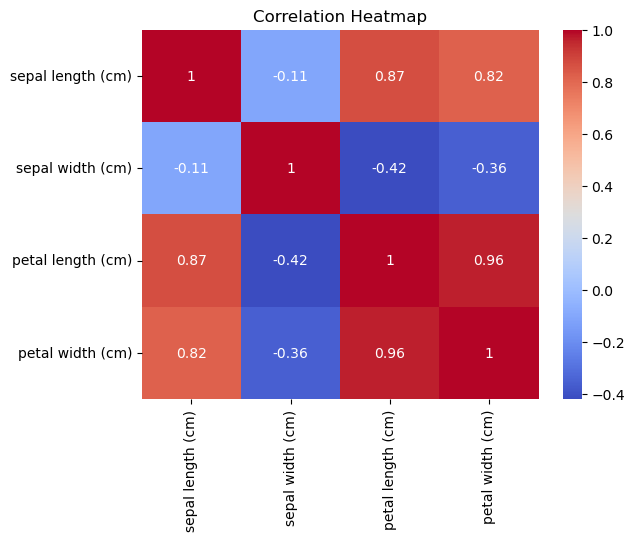

In [9]:
# Program 7: Correlation matrix and heatmap
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\iris_dataset.csv"    
df = pd.read_csv(FILE)
corr = df.select_dtypes(include="number").corr()
print(corr)
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()
# <-- change to your file path


In [10]:
# Program 8: One-sample t-test
import pandas as pd
from scipy import stats
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\diamonds.csv" # <-- change to your file path
COLUMN = None                       # column name; None = first numeric column
POP_MEAN = 70                       # hypothesised population mean
df = pd.read_csv(FILE)
if COLUMN is None:
    COLUMN = df.select_dtypes(include="number").columns[0]
sample = df[COLUMN].dropna()
t, p = stats.ttest_1samp(sample, POP_MEAN)
print("Column      :", COLUMN)
print("Sample mean :", sample.mean())
print("t-statistic :", t)
print("p-value     :", p)
if p < 0.05:
    print("Result: Reject H0 - the mean differs significantly from", POP_MEAN)
else:
    print("Result: Fail to reject H0 - no significant difference from", POP_MEAN)

Column      : carat
Sample mean : 0.7979397478680015
t-statistic : -33906.725572197916
p-value     : 0.0
Result: Reject H0 - the mean differs significantly from 70


In [11]:
# Program 9: Paired t-test (marks before and after training)
import pandas as pd
from scipy import stats
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\ecommerce_customer_behavior_dataset.csv" # <-- change to your file path
BEFORE = None                       # column name; None = 1st numeric column
AFTER = None                        # column name; None = 2nd numeric column
df = pd.read_csv(FILE)
num = df.select_dtypes(include="number").columns
if BEFORE is None:
    BEFORE = num[0]
if AFTER is None:
    AFTER = num[1]
data = df[[BEFORE, AFTER]].dropna()
t, p = stats.ttest_rel(data[BEFORE], data[AFTER])
print("Before:", BEFORE, "mean =", data[BEFORE].mean())
print("After :", AFTER, "mean =", data[AFTER].mean())
print("t-statistic:", t)
print("p-value    :", p)
if p < 0.05:
    print("Result: The training has a significant effect.")
else:
    print("Result: No significant effect of the training.")

Before: Age mean = 35.0326
After : Unit_Price mean = 455.8341199999999
t-statistic: -41.756865247240995
p-value    : 0.0
Result: The training has a significant effect.


In [12]:
# Program 10: Independent two-sample t-test
import pandas as pd
from scipy import stats
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\titanic.csv"  # <-- change to your file path
GROUP_COL = "Sex"                   # column that splits the data in two groups
VALUE_COL = "Age"                   # numeric column to compare
df = pd.read_csv(FILE)
g1_name, g2_name = df[GROUP_COL].dropna().unique()[:2]
group1 = df[df[GROUP_COL] == g1_name][VALUE_COL].dropna()
group2 = df[df[GROUP_COL] == g2_name][VALUE_COL].dropna()
t, p = stats.ttest_ind(group1, group2)
print(g1_name, "mean:", group1.mean())
print(g2_name, "mean:", group2.mean())
print("t-statistic:", t)
print("p-value    :", p)
if p < 0.05:
    print("Result: The two group means differ significantly.")
else:
    print("Result: No significant difference between the groups.")

male mean: 30.72664459161148
female mean: 27.915708812260537
t-statistic: 2.499206354920835
p-value    : 0.012671296797013709
Result: The two group means differ significantly.


In [49]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

print("OMP_NUM_THREADS =", os.environ["OMP_NUM_THREADS"])

OMP_NUM_THREADS = 1


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


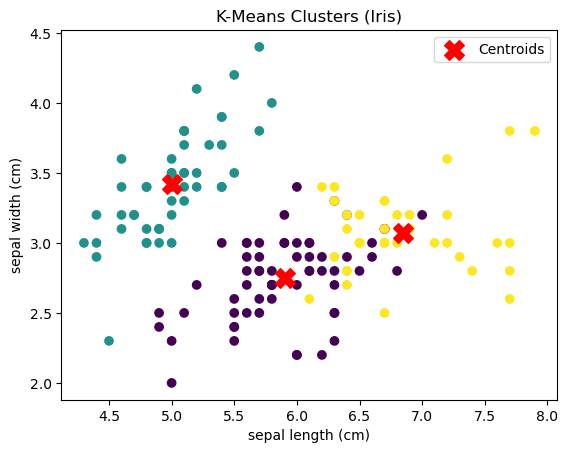

In [50]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4" # any number up to your core count
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\iris_dataset.csv"
df = pd.read_csv(FILE)
X = df.select_dtypes(include="number")
if "Id" in X.columns:
    X = X.drop(columns="Id")
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=labels, cmap="viridis")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="red", marker="X", s=200, label="Centroids")
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clusters (Iris)")
plt.legend()
plt.show()

In [14]:
# Program 12: Linear Regression on the Diabetes dataset
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\diabetes.csv"  # <-- change to your file path
df = pd.read_csv(FILE)
X = df.iloc[:, :-1]                 # all columns except the last = features
y = df.iloc[:, -1]                  # last column = target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Mean Squared Error:", mean_squared_error(y_test, pred))
print("R2 score          :", r2_score(y_test, pred))
# predict for new input data (here: first 3 rows of the test set as "new" data)
new_data = X_test.iloc[:3]
print("\nNew input:")
print(new_data)
print("Predicted values:", model.predict(new_data))

Mean Squared Error: 0.1710452728085009
R2 score          : 0.255002811767418

New input:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
668            6       98             58             33      190  34.0   
324            2      112             75             32        0  35.7   
624            2      108             64              0        0  30.8   

     DiabetesPedigreeFunction  Age  
668                     0.430   43  
324                     0.148   21  
624                     0.158   21  
Predicted values: [0.33550028 0.23809869 0.1510522 ]


Accuracy: 0.7467532467532467
Confusion Matrix:
[[78 21]
 [18 37]]


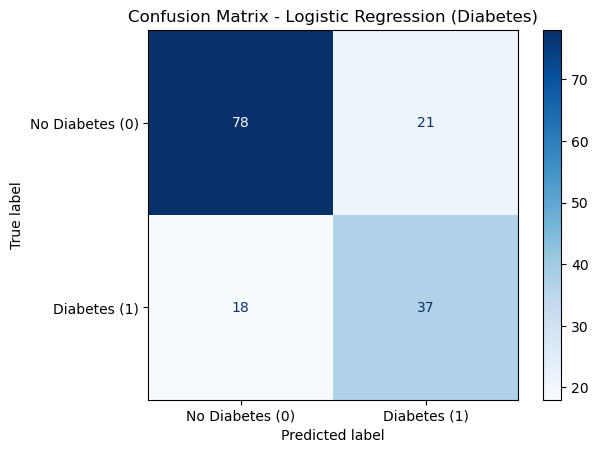

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\diabetes.csv"
df = pd.read_csv(FILE)
X = df.iloc[:, :-1]                 # features
y = df.iloc[:, -1]                  # last column = Outcome (0 or 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
cm = confusion_matrix(y_test, pred)
print("Confusion Matrix:")
print(cm)
# Confusion matrix as an image
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes (0)", "Diabetes (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression (Diabetes)")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")   # saves as an image file
plt.show()

In [16]:
# Program 14: Decision Tree classifier on Iris
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\iris_dataset.csv"  # <-- change to your file path
df = pd.read_csv(FILE)
if "Id" in df.columns:
    df = df.drop(columns="Id")
X = df.iloc[:, :-1]                 # features
y = df.iloc[:, -1]                  # last column = species
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))
# predict classes of new test samples (sepal length/width, petal length/width)
new_samples = pd.DataFrame([[5.1, 3.5, 1.4, 0.2],
                            [6.7, 3.0, 5.2, 2.3]], columns=X.columns)
print("Predictions for new samples:", model.predict(new_samples))

Accuracy: 1.0
Predictions for new samples: ['Iris-setosa' 'Iris-virginica']


Decision Tree accuracy : 0.7468
Decision Tree confusion matrix:
[[75 24]
 [15 40]]

Random Forest accuracy : 0.7208
Random Forest confusion matrix:
[[77 22]
 [21 34]]



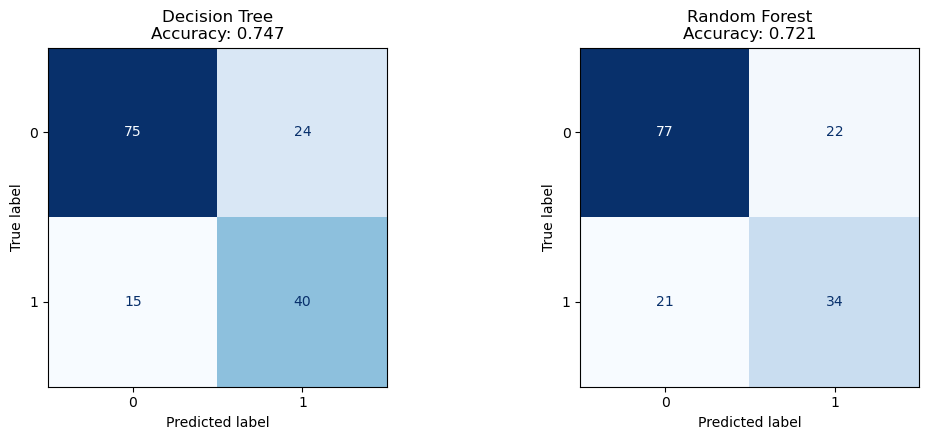

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\diabetes.csv"
TARGET = None                       # target column name; None = last column
df = pd.read_csv(FILE).dropna()
if TARGET is None:
    TARGET = df.columns[-1]
X = pd.get_dummies(df.drop(columns=TARGET))   # text columns -> numbers
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
models = {"Decision Tree": tree, "Random Forest": forest}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    print(f"{name} accuracy : {accuracy_score(y_test, pred):.4f}")
    print(f"{name} confusion matrix:")
    print(cm)
    print()
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{name}\nAccuracy: {accuracy_score(y_test, pred):.3f}")
plt.tight_layout()
plt.savefig("confusion_matrices_tree_vs_forest.png", dpi=150, bbox_inches="tight")
plt.show()


KNN accuracy: 0.7821229050279329
Confusion Matrix:
[[86 19]
 [20 54]]


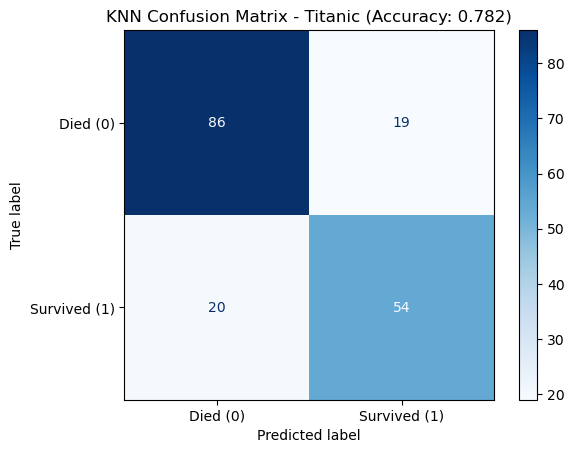

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\titanic.csv"
df = pd.read_csv(FILE)
df = df[["Survived", "Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]].copy()
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = df.dropna()
X = df.drop(columns="Survived")
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)
acc = accuracy_score(y_test, pred)
cm = confusion_matrix(y_test, pred)
print("KNN accuracy:", acc)
print("Confusion Matrix:")
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Died (0)", "Survived (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"KNN Confusion Matrix - Titanic (Accuracy: {acc:.3f})")
plt.savefig("confusion_matrix_knn.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# Program 17: SVM classifier on Iris
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\diabetes.csv"      # <-- change to your file path
df = pd.read_csv(FILE)
if "Id" in df.columns:
    df = df.drop(columns="Id")
X = df.iloc[:, :-1]
y = df.iloc[:, -1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = SVC(kernel="rbf")
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred))
print("\nClassification Report:")
print(classification_report(y_test, pred))

Accuracy: 0.7662337662337663

Confusion Matrix:
[[87 12]
 [24 31]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.88      0.83        99
           1       0.72      0.56      0.63        55

    accuracy                           0.77       154
   macro avg       0.75      0.72      0.73       154
weighted avg       0.76      0.77      0.76       154



Original shape   : (5000, 9)
Transformed shape: (5000, 2)
Variance explained by each component: [0.23605761 0.11924352]


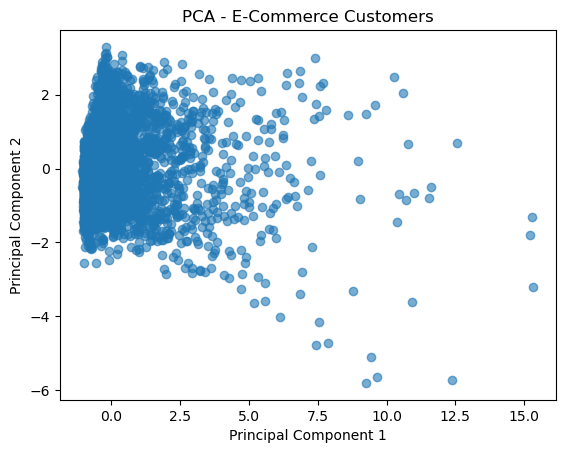

In [22]:
# Program 18: PCA on E-Commerce Customer Behavior dataset (reduce to 2D)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\ecommerce_customer_behavior_dataset.csv"  # <-- change to your file path
df = pd.read_csv(FILE)
X = df.select_dtypes(include="number").dropna()   # numeric features only
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Original shape   :", X.shape)
print("Transformed shape:", X_pca.shape)
print("Variance explained by each component:", pca.explained_variance_ratio_)
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - E-Commerce Customers")
plt.show()

Top 15 most common words:
movie : 85235
film : 76035
like : 39066
just : 34884
good : 28913
time : 23971
really : 23014
story : 22521
bad : 18004
great : 17936
people : 17710
dont : 16976
movies : 15722
films : 15539
way : 15373

Review length statistics:
count    50000.000000
mean       226.850260
std        168.175138
min          4.000000
25%        124.000000
50%        170.000000
75%        275.000000
max       2450.000000
Name: length, dtype: float64


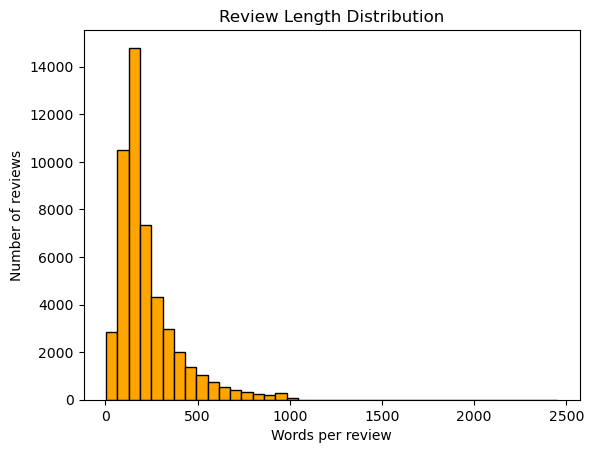

In [24]:
# Program 19: IMDb preprocessing - word frequency and review length
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\IMDB_Dataset.csv"   # <-- change to your file path
TEXT_COL = "review"
df = pd.read_csv(FILE)
def clean(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)        # remove HTML tags
    text = re.sub(r"[^a-z\s]", "", text)      # keep only letters
    return text
df["clean"] = df[TEXT_COL].apply(clean)
# word frequency (without stop words)
words = []
for review in df["clean"]:
    for w in review.split():
        if w not in ENGLISH_STOP_WORDS:
            words.append(w)
print("Top 15 most common words:")
for word, count in Counter(words).most_common(15):
    print(word, ":", count)
# review length (number of words)
df["length"] = df["clean"].apply(lambda t: len(t.split()))
print("\nReview length statistics:")
print(df["length"].describe())
plt.hist(df["length"], bins=40, color="orange", edgecolor="black")
plt.xlabel("Words per review")
plt.ylabel("Number of reviews")
plt.title("Review Length Distribution")
plt.show()

In [25]:
import re
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\IMDB_Dataset.csv"
TEXT_COL, LABEL_COL = "review", "sentiment"
df = pd.read_csv(FILE)
def clean(text):
    text = re.sub(r"<.*?>", " ", text.lower())
    return re.sub(r"[^a-z\s]", "", text)
df["clean"] = df[TEXT_COL].apply(clean)
# ---- sentiment model ---
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df[LABEL_COL], test_size=0.2, random_state=42)
vec = TfidfVectorizer(stop_words="english", max_features=5000)
model = LogisticRegression(max_iter=1000)
model.fit(vec.fit_transform(X_train), y_train)
acc = accuracy_score(y_test, model.predict(vec.transform(X_test)))
# ---- frequent words per sentiment ---
def top_words(sentiment, n=10):
    words = (w for r in df[df[LABEL_COL] == sentiment]["clean"] for w in r.split()
             if w not in ENGLISH_STOP_WORDS and len(w) > 2)
    return Counter(words).most_common(n)
pos, neg = top_words("positive"), top_words("negative")
table = pd.DataFrame({
    "Positive word": [w for w, _ in pos], "Count ": [c for _, c in pos],
    "Negative word": [w for w, _ in neg], "Count": [c for _, c in neg],
}, index=range(1, 11))
print("=" * 52)
print(f" IMDb Sentiment Analysis  |  Accuracy: {acc:.2%}")
print("=" * 52)
print("\n Top 10 most frequent words\n")
print(table.to_string())

 IMDb Sentiment Analysis  |  Accuracy: 88.47%

 Top 10 most frequent words

   Positive word  Count  Negative word  Count
1           film   40167         movie  48526
2          movie   36709          film  35868
3           like   17181          like  21885
4           good   14573          just  20903
5           just   13981           bad  14376
6          great   12812          good  14340
7          story   12613        really  12294
8           time   12130          time  11841
9         really   10720          dont  10283
10         films    8584         story   9908


Decision Tree accuracy: 0.7178
[[ 285   36    3    8    3]
 [  34  686  228   30   26]
 [  10  248 1297  343  484]
 [   4   47  354 2040  330]
 [   2   32  515  307 3436]] 

Random Forest accuracy: 0.7684
[[ 294   26    5    7    3]
 [  24  683  218   52   27]
 [   4  157 1104  579  538]
 [   1   18  200 2251  305]
 [   2   12  148  173 3957]] 

Ensemble accuracy: 0.7178
[[ 285   36    3    8    3]
 [  34  686  228   30   26]
 [  10  248 1297  343  484]
 [   4   47  354 2040  330]
 [   2   32  515  307 3436]] 



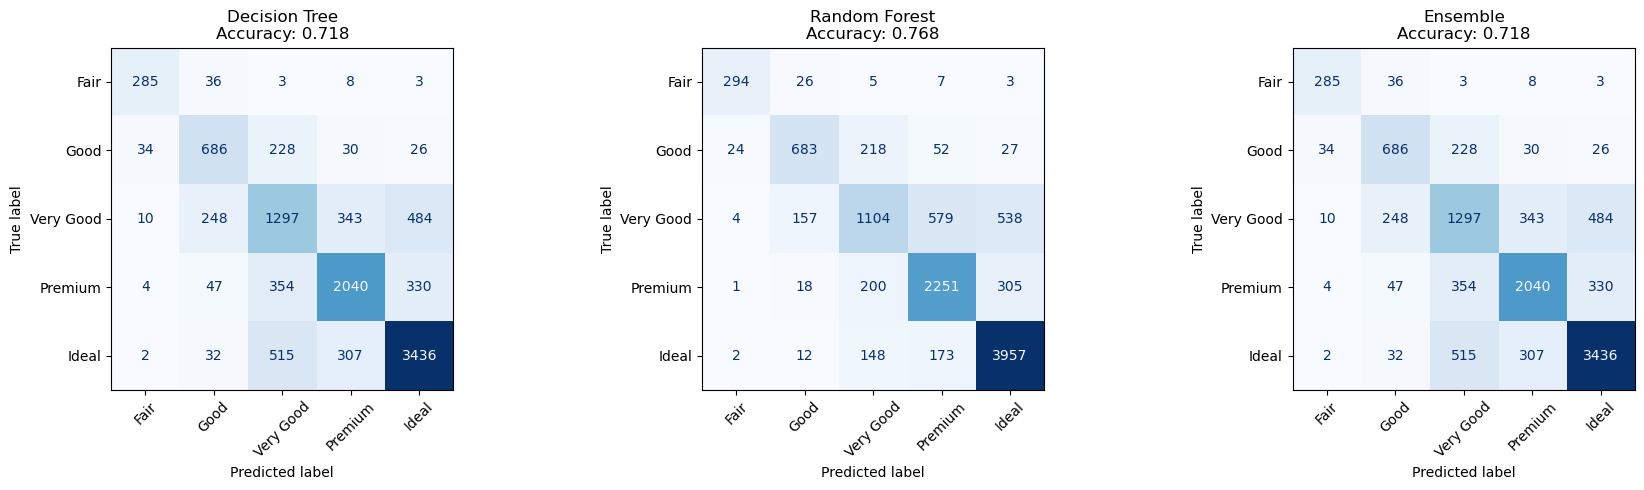

In [27]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # silences the joblib warning
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\diamonds.csv"
TARGET = "cut"
ORDER = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
df = pd.read_csv(FILE)
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]      # drop index column if present
X = pd.get_dummies(df.drop(columns=TARGET))               # color, clarity -> numbers
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
tree = DecisionTreeClassifier(random_state=42)
forest = RandomForestClassifier(n_estimators=100, random_state=42)
ensemble = VotingClassifier(estimators=[("tree", tree), ("forest", forest)], voting="soft")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, [("Decision Tree", tree), ("Random Forest", forest), ("Ensemble", ensemble)]):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    cm = confusion_matrix(y_test, pred, labels=ORDER)
    print(f"{name} accuracy: {acc:.4f}")
    print(cm, "\n")
    ConfusionMatrixDisplay(cm, display_labels=ORDER).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{name}\nAccuracy: {acc:.3f}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("confusion_matrices_diamonds.png", dpi=150, bbox_inches="tight")
plt.show()

In [41]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [42]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow installed successfully!")

TensorFlow version: 2.21.0
TensorFlow installed successfully!


Test accuracy: 0.7877094745635986
Confusion Matrix:
 [[94 11]
 [27 47]]


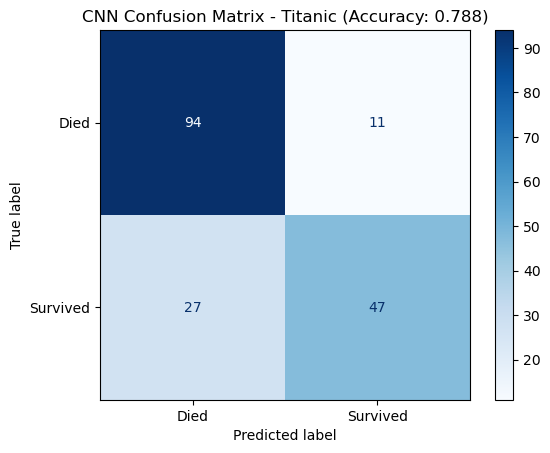

In [44]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\titanic.csv"
df = pd.read_csv(FILE)[["Survived", "Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]].copy()
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = df.dropna()
X, y = df.drop(columns="Survived"), df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train).reshape(-1, 6, 1)   # 6 features as a 1D sequence
X_test = sc.transform(X_test).reshape(-1, 6, 1)
model = keras.Sequential([
    layers.Input(shape=(6, 1)),
    layers.Conv1D(32, 2, activation="relu"),
    layers.Conv1D(64, 2, activation="relu"),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.1, verbose=0)
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy:", acc)
pred = (
    model.predict(X_test, batch_size=32, verbose=0) >= 0.5
).astype(int).ravel()
cm = confusion_matrix(y_test, pred)
print("Confusion Matrix:\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["Died", "Survived"]).plot(cmap="Blues", values_format="d")
plt.title(f"CNN Confusion Matrix - Titanic (Accuracy: {acc:.3f})")
plt.savefig("confusion_matrix_cnn_titanic.png", dpi=150, bbox_inches="tight")
plt.show()

k = 2  silhouette = 0.431
k = 3  silhouette = 0.14
k = 4  silhouette = 0.134
k = 5  silhouette = 0.13
k = 6  silhouette = 0.138

Best k: 2

Customers per cluster:
Cluster
1    4633
0     367
Name: count, dtype: int64

Average values of each cluster:
               Age   Unit_Price  Quantity  Discount_Amount  Total_Amount  \
Cluster                                                                    
0        34.212534  2399.982044  2.757493       178.838038   5878.388174   
1        35.097561   301.829741  2.177423        12.654967    595.332638   

         Session_Duration_Minutes  Pages_Viewed  Delivery_Time_Days  \
Cluster                                                               
0                       14.422343      8.940054            6.449591   
1                       14.585366      8.987697            6.500755   

         Customer_Rating  
Cluster                   
0               3.934605  
1               3.900281  


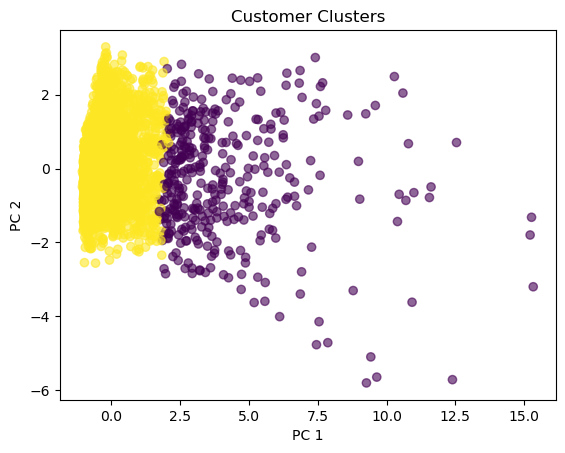

In [31]:
# Program 23: Cluster high-dimensional E-Commerce Customer Behavior data
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # hides TensorFlow info messages

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
FILE = r"C:\Users\Admin\Downloads\DataScience\MCA-Lab-Programs\Datasets\ecommerce_customer_behavior_dataset.csv" # <-- change to your file path
df = pd.read_csv(FILE)
X = df.select_dtypes(include="number").dropna()
X_scaled = StandardScaler().fit_transform(X)
# choose the number of clusters using the silhouette score
best_k, best_score = 2, -1
for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print("k =", k, " silhouette =", round(score, 3))
    if score > best_score:
        best_k, best_score = k, score
print("\nBest k:", best_k)
labels = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X_scaled)
X = X.copy()
X["Cluster"] = labels
print("\nCustomers per cluster:")
print(X["Cluster"].value_counts())
print("\nAverage values of each cluster:")
print(X.groupby("Cluster").mean())
# visualise in 2D using PCA
pts = PCA(n_components=2).fit_transform(X_scaled)
plt.scatter(pts[:, 0], pts[:, 1], c=labels, cmap="viridis", alpha=0.6)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("Customer Clusters")
plt.show()